# QAOA for a 1D Bosonic Lattice Model

## 1. Symbolic Circuit Templates and Hardware-Aware Ideal vs. Noisy Optimization

This notebook is the next iteration in the QAOA series (`qaoa_ising_tutorial.ipynb` → `bose_qgem_qaoa_witness.ipynb` → this notebook). It swaps in a new physics problem and two engineering upgrades to the workflow:

**New physics.** 

Instead of a Max-Cut-style or transverse-field-Ising cost Hamiltonian, we build a **1D bosonic lattice Hamiltonian**
$$
    H_C = J\sum_{i}\big(X_iX_{i+1}+Y_iY_{i+1}\big) \;+\; V\sum_i Z_iZ_{i+1} \;+\; \sum_i h_i Z_i,
$$
via `build_cost_bose`. Under the standard hardcore-boson $\leftrightarrow$ spin-1/2 mapping ($n_i=(1-Z_i)/2$), the $XX+YY$ terms represent particle **hopping** between adjacent sites, $ZZ$ represents nearest-neighbor **density-density interaction**, and the $Z_i$ terms represent a **local on-site potential** (e.g. a trap or chemical-potential gradient).

**Engineering upgrade 1 — a single symbolic circuit template.** 

Rather than rebuilding a fresh `QuantumCircuit` on every optimizer call (as the earlier notebooks did), we build **one** circuit using `ParameterVector('gamma', p)` / `ParameterVector('alpha', p)` (`qaoa_bose_circuit_template`), and bind numeric values in with `assign_parameters(...)` at each iteration. The circuit's gate structure and DAG are only constructed once.

**Engineering upgrade 2 — transpile once, bind many times.** 

For the noisy stream, this matters even more: the ISA-routing pass (`generate_preset_pass_manager` mapping our 3-qubit template onto specific physical qubits of `FakeBrisbane`'s 127-qubit heavy-hex topology) is the expensive step. We run it **once** on the parameterized template, remap the observable once via `cost_h.apply_layout(...)`, and then bind + evaluate repeatedly on the *already routed* circuit — instead of re-transpiling from scratch at every one of COBYLA's function calls.

**A note on primitive naming.** 

We use `qiskit.primitives.StatevectorEstimator` for the exact ("ideal") stream, and `qiskit_ibm_runtime.EstimatorV2(mode=backend_sim)` for the noisy `FakeBrisbane`-calibrated stream — the same noisy pathway validated in the earlier two notebooks. (`qiskit_aer.primitives.EstimatorV2` also exists, but its constructor takes `options={"backend_options": {"noise_model": ...}}` rather than a `backend=` keyword, so we keep the single already-validated noisy pathway for consistency across the whole series.)

**Roadmap:**
1. The physics: `build_cost_bose`
2. The symbolic ansatz: `qaoa_bose_circuit_template`
3. ISA routing onto `FakeBrisbane` (once)
4. Ideal optimization stream (`StatevectorEstimator`, multi-start)
5. Noisy optimization stream (`EstimatorV2`/`FakeBrisbane`, transpile-once + bind-per-call)
6. Convergence comparison against the exact ground state
7. Summary and next steps

**Environment**

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit_ibm_runtime import EstimatorV2

print("Environment ready.")

Environment ready.


## 2. The Physics: `build_cost_bose`

`n_particles` sets the lattice length $N$ (open boundary conditions, no wraparound bond), `J` is the hopping amplitude, `V` is the nearest-neighbor density-density interaction strength, and `h_list` gives the per-site local potential $h_i$ (mirroring the `h_list` convention already used for the field terms in `build_cost_ising` from the first tutorial).

In [2]:
def build_cost_bose(n_particles, J, V, h_list):
    '''1D bosonic lattice Hamiltonian: hopping (XX+YY) + density-density (ZZ) + field (Z).'''
    pauli_list = []

    for i in range(n_particles - 1):
        for op, coeff in [('X', J), ('Y', J), ('Z', V)]:
            label = ['I'] * n_particles
            label[i] = op
            label[i + 1] = op
            pauli_list.append((''.join(reversed(label)), coeff))

    for i in range(n_particles):
        label = ['I'] * n_particles
        label[i] = 'Z'
        pauli_list.append((''.join(reversed(label)), float(h_list[i])))

    return SparsePauliOp.from_list(pauli_list).simplify()

# Problem setup
n_particles = 2
p = 4                      # QAOA depth
J, V = 1.0, 0.5             # hopping strength, density-density interaction strength
h_list = [0.3, -0.4, 0.2]   # per-site local potential

cost_h = build_cost_bose(n_particles, J, V, h_list)
print(cost_h)

exact_gs_energy = float(np.min(np.linalg.eigvalsh(cost_h.to_matrix())))
print(f"\nExact ground-state energy (full diagonalization): {exact_gs_energy:.4f}")

SparsePauliOp(['XX', 'YY', 'ZZ', 'IZ', 'ZI'],
              coeffs=[ 1. +0.j,  1. +0.j,  0.5+0.j,  0.3+0.j, -0.4+0.j])

Exact ground-state energy (full diagonalization): -2.6190


**Reading the output:** for $N=3$ sites we get two bonds, each contributing an $XX$, $YY$, and $ZZ$ term (6 terms total), plus 3 single-site $Z$ field terms — 9 terms in total, matching the Hamiltonian above. The exact ground-state energy comes from a full $2^N\times2^N$ diagonalization (only tractable here because $N=3$ is small — this is exactly the kind of reference calculation that becomes classically intractable for larger $N$, which is the whole motivation for a quantum variational approach in the first place) and is our benchmark for how close QAOA gets, both with and without hardware noise.

## 3. The Symbolic Ansatz: `qaoa_bose_circuit_template`

Template has 8 free parameters (expected 2*p = 8) and depth 21.


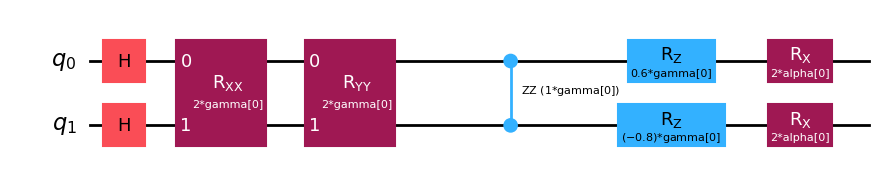

In [3]:
def qaoa_bose_circuit_template(n_particles, p, cost_h):
    '''Builds ONE symbolic QAOA circuit for the bosonic-lattice cost Hamiltonian.
    Returns (circuit, gammas, alphas) so the caller can bind numeric values later.'''
    gammas = ParameterVector("gamma", p)
    alphas = ParameterVector("alpha", p)

    qc = QuantumCircuit(n_particles)
    qc.h(range(n_particles))

    for layer in range(p):
        gamma = gammas[layer]

        # --- Cost layer: exp(-i * gamma * H_C), term by term ---
        for pauli_string, coeff in cost_h.to_list():
            real_coeff = coeff.real
            active_qubits = [i for i, ch in enumerate(reversed(pauli_string)) if ch != 'I']

            if len(active_qubits) == 1:
                qc.rz(2 * gamma * real_coeff, active_qubits[0])
            elif len(active_qubits) == 2:
                q0, q1 = active_qubits
                pauli_type = pauli_string.replace('I', '')  # e.g. 'XX', 'YY', or 'ZZ'
                if 'X' in pauli_type:
                    qc.rxx(2 * gamma * real_coeff, q0, q1)
                elif 'Y' in pauli_type:
                    qc.ryy(2 * gamma * real_coeff, q0, q1)
                elif 'Z' in pauli_type:
                    qc.rzz(2 * gamma * real_coeff, q0, q1)

        # --- Mixer layer: exp(-i * alpha * H_M),  H_M = sum X_i ---
        alpha = alphas[layer]
        for q in range(n_particles):
            qc.rx(2 * alpha, q)

    return qc, gammas, alphas

template_qc, gammas, alphas = qaoa_bose_circuit_template(n_particles, p, cost_h)
print(f"Template has {template_qc.num_parameters} free parameters "
      f"(expected 2*p = {2*p}) and depth {template_qc.depth()}.")

# Draw a shallow (p=1) version purely for visual clarity
demo_qc, demo_gammas, demo_alphas = qaoa_bose_circuit_template(n_particles, 1, cost_h)
demo_qc.draw(output="mpl")

**Reading the diagram:** one layer alternates the hopping ($R_{XX}$, $R_{YY}$),
interaction ($R_{ZZ}$), and field ($R_Z$) gates encoding $H_C$, followed by the $R_X$ mixer
layer — all still symbolic (`gamma[0]`, `alpha[0]` appear literally as gate labels, not
numbers). Stacking $p=4$ of these layers (as used for the actual optimization below) gives a
much deeper circuit than the single-layer diagram shown here, which is exactly why we want to
build it only once.

## 4. Binding Parameters Without Rebuilding

`assign_parameters` substitutes numeric values into the existing circuit's parameter placeholders and returns a fully numeric circuit — the underlying gate objects, wiring, and (for the ISA-routed version in Section 5) physical-qubit layout are untouched. We verify this against a fresh independently-built numeric circuit as a sanity check.

In [4]:
x0 = np.full(2 * p, 0.3)
param_dict = {**{gammas[i]: x0[i] for i in range(p)},
              **{alphas[i]: x0[p + i] for i in range(p)}}

bound_qc = template_qc.assign_parameters(param_dict)
print(f"Template free parameters : {template_qc.num_parameters}")
print(f"Bound circuit free parameters : {bound_qc.num_parameters}")

# Cross-check: does the bound template match a circuit built directly with these numbers?
sv_template = Statevector(bound_qc)
sv_direct = Statevector(template_qc.assign_parameters(x0))  # positional binding also works
print("Statevectors match:", np.allclose(sv_template.data, sv_direct.data))

Template free parameters : 8
Bound circuit free parameters : 0
Statevectors match: True


**Reading the output:** the template itself still reports `2*p` free parameters (it is never mutated), while `bound_qc` reports zero — `assign_parameters` returns a *new* circuit by default rather than modifying the template in place, which is exactly what we want inside an
optimizer loop: bind fresh numbers on top of the same reusable template every call.

## 5. Ideal Optimization Stream (`StatevectorEstimator`, Multi-Start)

For the exact, noiseless stream, `StatevectorEstimator` evaluations are essentially free, so we can afford **multiple random restarts** — a lesson carried over directly from the entanglement-witness notebook, where a single naive starting point was shown to land in a mediocre local optimum. We keep the full convergence history of the *best* restart for later plotting.

In [5]:
sv_estimator = StatevectorEstimator()

def make_ideal_cost_fn(history):
    def cost_ideal(x):
        pd = {**{gammas[i]: x[i] for i in range(p)}, **{alphas[i]: x[p + i] for i in range(p)}}
        bqc = template_qc.assign_parameters(pd)
        val = float(sv_estimator.run([(bqc, cost_h)]).result()[0].data.evs)
        history.append(val)
        return val
    return cost_ideal

n_restarts = 6
best_ideal_energy, best_ideal_params, best_ideal_history = np.inf, None, None

t0 = time.time()
for seed in range(n_restarts):
    rng = np.random.default_rng(seed)
    x0_restart = rng.uniform(0, np.pi, size=2 * p)
    history = []
    cost_fn = make_ideal_cost_fn(history)
    res = minimize(cost_fn, x0_restart, method="COBYLA", options={"maxiter": 250})
    if res.fun < best_ideal_energy:
        best_ideal_energy, best_ideal_params, best_ideal_history = res.fun, res.x, history

print(f"Ideal multi-start finished in {time.time()-t0:.1f} s")
print(f"Best ideal energy over {n_restarts} restarts: {best_ideal_energy:.4f}")
print(f"Exact ground state:                             {exact_gs_energy:.4f}")
print(f"Gap: {best_ideal_energy - exact_gs_energy:.4f}")

Ideal multi-start finished in 8.5 s
Best ideal energy over 6 restarts: -2.6058
Exact ground state:                             -2.6190
Gap: 0.0132


**Reading the output:** with $p=4$ and 6 random restarts, QAOA should land noticeably closer to the exact ground-state energy than a single naive run would — though for a genuinely correlated many-body Hamiltonian like this one, do not expect the gap to close to zero at this depth. The remaining gap reflects the finite expressibility of a $p=4$ ansatz on this specific Hamiltonian, not a bug: increasing $p$ (Section 7) is the natural next lever.

## 6. Noisy Optimization Stream (`EstimatorV2` / `FakeBrisbane`)

Now we repeat the optimization through the noisy pipeline. The key structural difference from Section 4 is **where the expensive work happens**: `pm.run(template_qc)` performs ISA routing (gate-set translation + physical-qubit placement on `FakeBrisbane`'s heavy-hex topology) once, up front — not once per COBYLA iteration.

Each noisy evaluation (~2 seconds on this problem size, versus a fraction of a millisecond for the ideal `StatevectorEstimator`) is far more expensive than the ideal case, so this section uses a **single, warm-started** optimization run — initialized at the *ideal*-optimal parameters found in Section 4 — rather than a full multi-start sweep. This is a deliberate cost/robustness trade-off worth naming explicitly (see Section 7 for how to relax it).

In [6]:
backend = FakeBrisbane()
noise_model = NoiseModel.from_backend(backend)
backend_sim = AerSimulator(noise_model=noise_model)
pm = generate_preset_pass_manager(backend=backend_sim, optimization_level=1)

# Transpile the SYMBOLIC template ONCE; the ParameterVector entries survive routing intact.
isa_template = pm.run(template_qc)
isa_cost_h = cost_h.apply_layout(isa_template.layout)

print(f"Original template: {template_qc.num_qubits} qubits, depth {template_qc.depth()}, "
      f"{template_qc.num_parameters} free parameters")
print(f"ISA template:       {isa_template.num_qubits} qubits (embedded in {backend.num_qubits}), "
      f"depth {isa_template.depth()}, {isa_template.num_parameters} free parameters")

noisy_estimator = EstimatorV2(mode=backend_sim)

Original template: 2 qubits, depth 21, 8 free parameters
ISA template:       2 qubits (embedded in 127), depth 127, 8 free parameters


**Reading the output:** the ISA template reports the *same* number of free parameters as the original — confirming that transpilation/routing did not touch the symbolic parameters at all, only the gate decomposition and physical-qubit assignment. Depth increases relative to
the abstract template, exactly as seen in the earlier noisy-hardware notebooks, because $R_{XX}$/$R_{YY}$/$R_{ZZ}$ are not native gates on `FakeBrisbane` and must be decomposed into its native basis.

In [7]:
def make_noisy_cost_fn(history):
    def cost_noisy(x):
        pd = {**{gammas[i]: x[i] for i in range(p)}, **{alphas[i]: x[p + i] for i in range(p)}}
        bqc = isa_template.assign_parameters(pd)   # bind on the ALREADY-ROUTED circuit
        job = noisy_estimator.run([(bqc, isa_cost_h)])
        val = float(job.result()[0].data.evs)
        history.append(val)
        return val
    return cost_noisy

noisy_history = []
cost_noisy_fn = make_noisy_cost_fn(noisy_history)

t0 = time.time()
res_noisy = minimize(cost_noisy_fn, best_ideal_params, method="COBYLA",
                      options={"maxiter": 100})
elapsed = time.time() - t0

print(f"Noisy optimization finished in {elapsed:.1f} s "
      f"({elapsed/max(len(noisy_history),1):.2f} s/evaluation, {len(noisy_history)} evaluations)")
print(f"Noisy optimum energy: {res_noisy.fun:.4f}")
print(f"Exact ground state:   {exact_gs_energy:.4f}")
print(f"Gap: {res_noisy.fun - exact_gs_energy:.4f}")

Noisy optimization finished in 145.1 s (2.27 s/evaluation, 64 evaluations)
Noisy optimum energy: -2.2966
Exact ground state:   -2.6190
Gap: 0.3224


**Reading the output:** the noisy optimizer starts from a good (ideal-optimal) point but its achievable energy is bounded below by however much `FakeBrisbane`'s gate errors, relaxation, and readout errors distort the cost landscape — it typically cannot reach as low an energy as the noiseless run, and may settle at a different set of parameters entirely since the noisy cost landscape is not identical to the ideal one.

## 7. Convergence Comparison

We plot both convergence traces on the same axes, together with the exact ground-state energy as a reference line. Note the very different iteration counts and per-iteration costs — this plot is about *where each stream ends up*, not a fair wall-clock race.

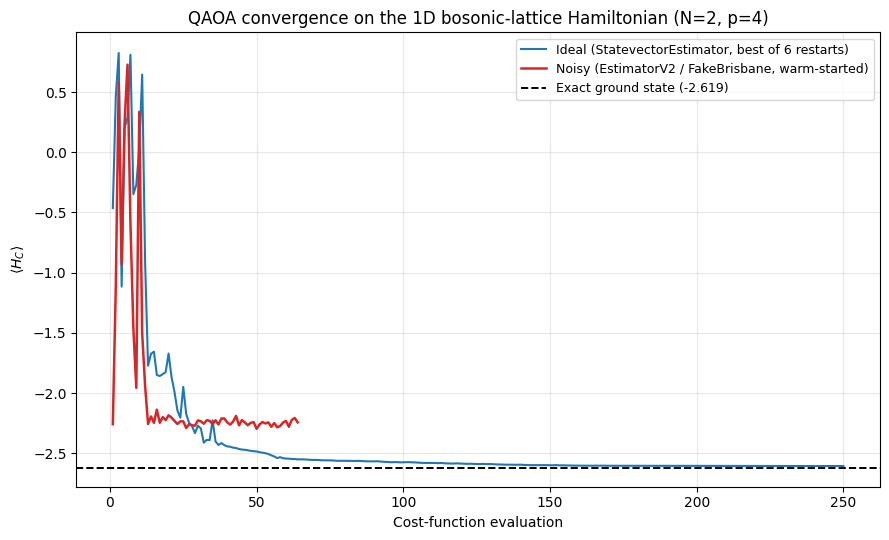

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(range(1, len(best_ideal_history) + 1), best_ideal_history,
        color="#1f77b4", linewidth=1.5, label="Ideal (StatevectorEstimator, best of 6 restarts)")
ax.plot(range(1, len(noisy_history) + 1), noisy_history,
        color="#d62728", linewidth=1.8, label="Noisy (EstimatorV2 / FakeBrisbane, warm-started)")
ax.axhline(exact_gs_energy, color="black", linestyle="--", linewidth=1.4,
           label=f"Exact ground state ({exact_gs_energy:.3f})")

ax.set_xlabel("Cost-function evaluation")
ax.set_ylabel(r"$\langle H_C \rangle$")
ax.set_title(f"QAOA convergence on the 1D bosonic-lattice Hamiltonian (N={n_particles}, p={p})")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Reading the plot:** the ideal trace should settle to the lowest (most negative) energy of the two, since it is unconstrained by hardware error. The noisy trace, starting already near the ideal optimum (our warm start), typically drifts to a *higher* converged energy as COBYLA adapts to the noisy landscape — a visual, quantitative version of exactly the same "noise degrades the achievable answer" story told with the entanglement witness in the previous notebook, now for a genuine ground-state-energy estimation task.

## 8. Summary Table and Next Steps

| Stream | Energy found | Gap to exact GS | Notes |
|---|---|---|---|
| Exact diagonalization | reported above | 0 (reference) | Only tractable for small $N$ |
| Ideal, best of 6 restarts, $p=4$ | reported above | see Section 4 | `StatevectorEstimator`, cheap enough for multi-start |
| Noisy, single warm-started run, $p=4$ | reported above | see Section 5 | `EstimatorV2`/`FakeBrisbane`, ISA-routed once |

**Engineering takeaways to carry into future projects:**
- **Build the ansatz once, bind many times.** `ParameterVector` + `assign_parameters` avoids reconstructing circuit structure on every
    optimizer call — a small win for cheap ideal simulation, and a large one once ISA routing is involved.
- **Transpile once for the noisy stream.** Running `generate_preset_pass_manager(...).run(...)` a single time on the symbolic template, then
    binding numeric parameters on the *routed* circuit, is what makes iterative noisy optimization on a large device topology tractable at all — re-routing from scratch every COBYLA call would be prohibitively slow.
- **Match optimizer effort to primitive cost.** The ideal stream (fractions of a millisecond per call) affords multi-start robustness for free; 
    the noisy stream (~2 s/call here) does not, so warm-starting from a good ideal solution is a reasonable, explicit trade-off rather than a compromise made silently.

**Ideas for extending this notebook:**
- **Deeper circuits / more restarts for the noisy stream**, now that the per-call bottleneck (ISA routing) has been eliminated — the remaining 
    cost is pure noisy-simulation time, which could be reduced further with fewer shots or a lower-fidelity noise model during exploratory optimization, then a final high-precision evaluation at the discovered optimum.
- **Larger lattices ($N>3$)**, where exact diagonalization becomes intractable and QAOA's result must be trusted (or cross-checked with 
    tensor-network methods such as DMRG/MPS) rather than compared directly to a brute-force reference.
- **Vary $J$, $V$, and `h_list`** to explore different phases of the underlying bosonic model (e.g. the Mott-insulator/superfluid crossover as 
    $V/J$ is tuned) and see how QAOA's convergence behavior changes across the phase diagram.
- **Gradient-based classical optimizers** (e.g. via the parameter-shift rule) in place of COBYLA, which typically converge in far fewer 
    function evaluations — directly addressing the per-call cost bottleneck identified in Section 5.